In [1]:
from pathlib import Path 
import csv
import numpy as np
import torch

Se busca la raíz del proyecto desde la ubicación del notebook


In [ ]:
current = Path.cwd().resolve()
ROOT = None 

for folder in (current,) + tuple(current.parents):
    if(folder/"data"/"train"/"X.npy").is_file():
        ROOT = folder 
        break
    
if ROOT is None:
    raise FileNotFoundError(
        "No se encontro data/train/X.npy. "
        "Abre el notebook dentro de coms_proyecto2"
    )

DATA_DIR = ROOT / "data"

from src.pre_procesamiento import CLASSES, normalize_iq_batch


Convertir el nombre de cada clae en un número


In [3]:
CLASS_TO_INDEX = {
    name:index 
    for index, name in enumerate(CLASSES)
}

print("Proyecto:", ROOT)
print("Etiquetas:", CLASS_TO_INDEX)

Proyecto: /home/lcmj2803/coms_proyecto2
Etiquetas: {'BPSK': 0, 'QPSK': 1, '8PSK': 2, '16QAM': 3, '64QAM': 4, '16APSK': 5, 'ruido': 6}


In [4]:
def load_iq_split(split):
    folder = DATA_DIR / split
    
    iq = np.load(
        str(folder / "X.npy"),
        mmap_mode= "r",
        allow_pickle=False
        
    )
    
    with (folder /"meta.csv").open(
        "r", newline="",encoding = "utf-8") as file:
        metadata = list(csv.DictReader(file))
        
    if iq.ndim != 3 or iq.shape[1:] != (2,1024):
        raise ValueError(
            "{}: se esperaba una forma (N,2,1024)".format(split)
        )
        
    if iq.dtype != np.float32:
        raise ValueError(
            "{}: las señales deben ser float32.".format(split)
        )

    if len(metadata) != len(iq):
        raise ValueError(
            "{}: señales y metadatos tienen distinta longitud.".format(split)
        )

    labels = np.array(
        [CLASS_TO_INDEX[row["mod"]] for row in metadata],
        dtype=np.int64
    )

    esn0_db = np.array(
        [float(row["snr_db"]) for row in metadata],
        dtype=np.float64
    )

    print(
        "{}: señales {}, etiquetas {}".format(
            split, iq.shape, labels.shape
        )
    )

    return iq, labels, esn0_db


iq_train, labels_train, esn0_train = load_iq_split("train")
iq_val, labels_val, esn0_val = load_iq_split("val")

train: señales (56000, 2, 1024), etiquetas (56000,)
val: señales (11200, 2, 1024), etiquetas (11200,)


In [6]:
for split, iq in (("train", iq_train), ("val", iq_val)):
    example = normalize_iq_batch(iq[:8])

    means = np.mean(example, axis=2)

    powers = np.mean(
        example[:, 0, :] ** 2 + example[:, 1, :] ** 2,
        axis=1
    )

    print("\nConjunto:", split)
    print("Forma:", example.shape)
    print("Tipo:", example.dtype)
    print("Máxima media absoluta:", np.max(np.abs(means)))
    print("Potencias:", powers)

    np.testing.assert_allclose(
        means, 0.0, atol=1e-6, rtol=0
    )

    np.testing.assert_allclose(
        powers, 1.0, atol=1e-6, rtol=0
    )

print("\nCorrecto: normalización verificada en ambos lotes.")


Conjunto: train
Forma: (8, 2, 1024)
Tipo: float32
Máxima media absoluta: 1.1641532e-08
Potencias: [1.0000001  0.9999999  0.99999994 1.         1.         1.
 1.         1.0000001 ]

Conjunto: val
Forma: (8, 2, 1024)
Tipo: float32
Máxima media absoluta: 1.071021e-08
Potencias: [1.0000001  0.9999999  1.         1.         0.99999994 1.
 1.         0.9999999 ]

Correcto: normalización verificada en ambos lotes.


In [14]:
import sys

# Permitir importar src desde la carpeta notebooks.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.models import ModulationCNN

MODEL_SEED = 42
torch.manual_seed(MODEL_SEED)

device = torch.device("cpu")

cnn = ModulationCNN(
    num_classes=len(CLASSES)
).to(device)

print(cnn)

num_parameters = sum(
    parameter.numel()
    for parameter in cnn.parameters()
    if parameter.requires_grad
)

print("Parámetros entrenables:", num_parameters)

ModulationCNN(
  (features): Sequential(
    (0): Conv1d(2, 16, kernel_size=(7,), stride=(1,), padding=(3,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (7): ReLU()
    (8): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Linear(in_features=64, out_features=7, bias=True)
)
Parámetros entrenables: 13591


In [8]:
from torch.utils.data import Dataset, DataLoader


class IQDataset(Dataset):
    def __init__(self, iq, labels):
        if len(iq) != len(labels):
            raise ValueError("Las señales y etiquetas no coinciden en cantidad.")

        self.iq = iq
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.iq[index], self.labels[index]

In [9]:
def prepare_batch(items):
    signals, labels = zip(*items)

    signals = np.stack(signals, axis=0)
    signals = normalize_iq_batch(signals)

    return (
        torch.from_numpy(signals),
        torch.from_numpy(np.array(labels, dtype=np.int64))
    )


train_dataset = IQDataset(iq_train, labels_train)
val_dataset = IQDataset(iq_val, labels_val)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    collate_fn=prepare_batch
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=prepare_batch
)

print("Lotes de train:", len(train_loader))
print("Lotes de val:", len(val_loader))

Lotes de train: 875
Lotes de val: 175


Lotes de train: 875
Lotes de val: 175


In [10]:
# Obtener un lote de validación.
signals_batch, labels_batch = next(iter(val_loader))

# Preparar la red para evaluación.
cnn.eval()

# Hacer la predicción sin calcular gradientes.
with torch.no_grad():
    scores = cnn(signals_batch.to(device))

print("Entrada:", tuple(signals_batch.shape))
print("Etiquetas:", tuple(labels_batch.shape))
print("Salida:", tuple(scores.shape))

# Comprobar dimensiones y valores.
assert tuple(signals_batch.shape[1:]) == (2, 1024)

assert tuple(scores.shape) == (
    signals_batch.shape[0],
    len(CLASSES)
)

assert torch.isfinite(scores).all().item()

print("Correcto: una puntuación por clase y por observación.")

Entrada: (64, 2, 1024)
Etiquetas: (64,)
Salida: (64, 7)
Correcto: una puntuación por clase y por observación.


In [11]:
cnn.eval()

correct = 0
total = 0

# Contar cuántas veces predice cada clase.
prediction_counts = np.zeros(len(CLASSES), dtype=np.int64)

with torch.no_grad():
    for signals, labels in val_loader:
        signals = signals.to(device)
        labels = labels.to(device)

        scores = cnn(signals)

        # Índice de la puntuación más alta de cada observación.
        predictions = scores.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        prediction_counts += np.bincount(
            predictions.cpu().numpy(),
            minlength=len(CLASSES)
        )

assert total == len(val_dataset)

accuracy_initial = correct / float(total)

print("Observaciones evaluadas:", total)
print("Aciertos:", correct)
print("Exactitud sin entrenar: {:.2%}".format(accuracy_initial))
print("Referencia de azar: {:.2%}".format(1.0 / len(CLASSES)))

print("\nPredicciones por clase:")

for name, count in zip(CLASSES, prediction_counts):
    print("{}: {}".format(name, count))

Observaciones evaluadas: 11200
Aciertos: 1600
Exactitud sin entrenar: 14.29%
Referencia de azar: 14.29%

Predicciones por clase:
BPSK: 0
QPSK: 0
8PSK: 0
16QAM: 0
64QAM: 11200
16APSK: 0
ruido: 0


In [15]:
import time
from torch import nn

LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    cnn.parameters(),
    lr=LEARNING_RATE
)

# Aquí iremos registrando los resultados de cada época.
history = []

In [16]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    loss_sum = 0.0
    correct = 0
    total = 0

    for batch_index, (signals, labels) in enumerate(loader, start=1):
        signals = signals.to(device)
        labels = labels.to(device)

        # Limpiar los gradientes del lote anterior.
        optimizer.zero_grad()

        # Calcular las puntuaciones y el error.
        scores = model(signals)
        loss = criterion(scores, labels)

        if not torch.isfinite(loss).item():
            raise ValueError("La pérdida no es finita.")

        # Calcular gradientes y actualizar los parámetros.
        loss.backward()
        optimizer.step()

        # Acumular resultados, ponderando por tamaño de lote.
        batch_size = labels.size(0)

        loss_sum += loss.item() * batch_size
        correct += (scores.argmax(dim=1) == labels).sum().item()
        total += batch_size

        if batch_index % 100 == 0 or batch_index == len(loader):
            print(
                "Lote {}/{} | Pérdida: {:.4f} | Exactitud: {:.2%}".format(
                    batch_index,
                    len(loader),
                    loss_sum / total,
                    correct / float(total)
                ),
                flush=True
            )

    return loss_sum / total, correct / float(total)


def evaluate(model, loader, criterion, device):
    model.eval()

    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for signals, labels in loader:
            signals = signals.to(device)
            labels = labels.to(device)

            scores = model(signals)
            loss = criterion(scores, labels)

            if not torch.isfinite(loss).item():
                raise ValueError("La pérdida de validación no es finita.")

            batch_size = labels.size(0)

            loss_sum += loss.item() * batch_size
            correct += (scores.argmax(dim=1) == labels).sum().item()
            total += batch_size

    return loss_sum / total, correct / float(total)

In [13]:
epoch = len(history) + 1

print("Comenzando época {}...".format(epoch), flush=True)

start = time.perf_counter()

train_loss, train_accuracy = train_one_epoch(
    cnn,
    train_loader,
    criterion,
    optimizer,
    device
)

train_seconds = time.perf_counter() - start

print("\nEvaluando en val...", flush=True)

start_val = time.perf_counter()

val_loss, val_accuracy = evaluate(
    cnn,
    val_loader,
    criterion,
    device
)

val_seconds = time.perf_counter() - start_val

history.append({
    "epoch": epoch,
    "train_loss": train_loss,
    "train_accuracy": train_accuracy,
    "val_loss": val_loss,
    "val_accuracy": val_accuracy,
    "train_seconds": train_seconds,
    "val_seconds": val_seconds
})

print("\nÉpoca {} terminada".format(epoch))
print("Pérdida train: {:.4f}".format(train_loss))
print("Pérdida val:   {:.4f}".format(val_loss))
print("Exactitud train: {:.2%}".format(train_accuracy))
print("Exactitud val:   {:.2%}".format(val_accuracy))
print("Tiempo de entrenamiento: {:.2f} min".format(train_seconds / 60.0))
print("Tiempo de validación: {:.2f} min".format(val_seconds / 60.0))
print(
    "Tiempo total: {:.2f} min".format(
        (train_seconds + val_seconds) / 60.0
    )
)

NameError: name 'history' is not defined

In [20]:
import copy
import json
import matplotlib.pyplot as plt

MODEL_DIR = ROOT / "models"
FIG_DIR = ROOT / "figs" / "cnn"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "cnn.pt"

# Esta celda parte de la primera época ya terminada.
assert len(history) == 1, (
    "Se esperaba una sola época en history. "
    "No reinicies el historial si ya entrenaste más."
)

best_record = history[0].copy()

# Copia independiente: no cambiará al seguir entrenando cnn.
best_cnn = copy.deepcopy(cnn).cpu()
best_cnn.eval()

torch.save(best_cnn.state_dict(), str(MODEL_PATH))

print("Primera época guardada en:", MODEL_PATH)
print("Pérdida val: {:.4f}".format(best_record["val_loss"]))

Primera época guardada en: /home/lcmj2803/coms_proyecto2/models/cnn.pt
Pérdida val: 1.7311


In [23]:
TOTAL_EPOCHS = 30

for epoch in range(len(history) + 1, TOTAL_EPOCHS + 1):
    print(
        "\nComenzando época {}/{}".format(epoch, TOTAL_EPOCHS),
        flush=True
    )

    start = time.perf_counter()

    train_loss, train_accuracy = train_one_epoch(
        cnn, train_loader, criterion, optimizer, device
    )

    train_seconds = time.perf_counter() - start

    start_val = time.perf_counter()

    val_loss, val_accuracy = evaluate(
        cnn, val_loader, criterion, device
    )

    val_seconds = time.perf_counter() - start_val

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "train_seconds": train_seconds,
        "val_seconds": val_seconds
    }

    history.append(record)

    # Conservar el modelo con menor pérdida de validación.
    if val_loss < best_record["val_loss"]:
        best_record = record.copy()
        best_cnn = copy.deepcopy(cnn).cpu()
        best_cnn.eval()

        torch.save(best_cnn.state_dict(), str(MODEL_PATH))

        print("Nuevo mejor modelo guardado.", flush=True)

    # Guardar resultados numéricos de todas las épocas.
    with (MODEL_DIR / "cnn_history.json").open(
        "w", encoding="utf-8"
    ) as file:
        json.dump(history, file, indent=2)

    print(
        "Época {} | Pérdida train: {:.4f} | Pérdida val: {:.4f}".format(
            epoch, train_loss, val_loss
        )
    )

    print(
        "Exactitud train: {:.2%} | Exactitud val: {:.2%} | "
        "Tiempo: {:.2f} min".format(
            train_accuracy,
            val_accuracy,
            (train_seconds + val_seconds) / 60.0
        ),
        flush=True
    )

print("\nEntrenamiento terminado.")
print("Mejor época por pérdida val:", best_record["epoch"])
print("Mejor pérdida val: {:.4f}".format(best_record["val_loss"]))
print(
    "Exactitud val de ese modelo: {:.2%}".format(
        best_record["val_accuracy"]
    )
)


Comenzando época 11/30
Lote 100/875 | Pérdida: 1.3804 | Exactitud: 43.00%
Lote 200/875 | Pérdida: 1.3738 | Exactitud: 43.62%
Lote 300/875 | Pérdida: 1.3780 | Exactitud: 43.66%
Lote 400/875 | Pérdida: 1.3752 | Exactitud: 43.62%
Lote 500/875 | Pérdida: 1.3726 | Exactitud: 43.77%
Lote 600/875 | Pérdida: 1.3740 | Exactitud: 43.71%
Lote 700/875 | Pérdida: 1.3723 | Exactitud: 43.84%
Lote 800/875 | Pérdida: 1.3720 | Exactitud: 43.89%
Lote 875/875 | Pérdida: 1.3712 | Exactitud: 43.92%
Época 11 | Pérdida train: 1.3712 | Pérdida val: 1.3729
Exactitud train: 43.92% | Exactitud val: 43.50% | Tiempo: 0.41 min

Comenzando época 12/30
Lote 100/875 | Pérdida: 1.3794 | Exactitud: 44.20%
Lote 200/875 | Pérdida: 1.3749 | Exactitud: 44.09%
Lote 300/875 | Pérdida: 1.3679 | Exactitud: 44.48%
Lote 400/875 | Pérdida: 1.3667 | Exactitud: 44.71%
Lote 500/875 | Pérdida: 1.3670 | Exactitud: 44.49%
Lote 600/875 | Pérdida: 1.3667 | Exactitud: 44.54%
Lote 700/875 | Pérdida: 1.3661 | Exactitud: 44.52%
Lote 800/875 |

Figura guardada: 01_perdida_train_val


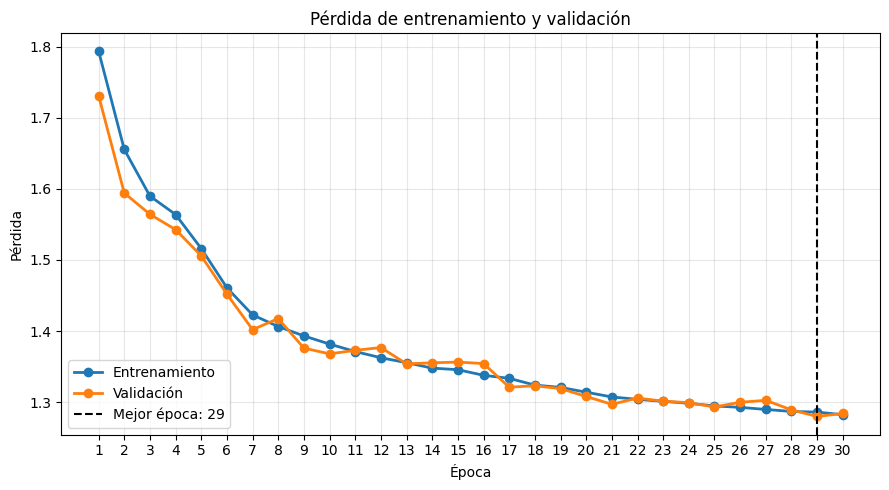

Figura guardada: 02_exactitud_train_val


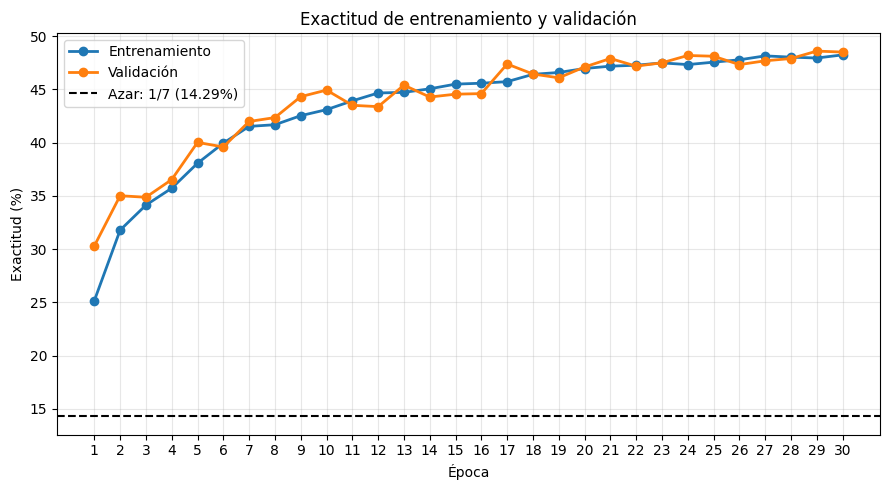

 Época   Pérdida train   Pérdida val   Exactitud val
     1          1.7938        1.7311         30.29%
     2          1.6555        1.5942         35.01%
     3          1.5898        1.5642         34.87%
     4          1.5639        1.5427         36.53%
     5          1.5161        1.5058         40.02%
     6          1.4609        1.4520         39.59%
     7          1.4228        1.4020         41.98%
     8          1.4064        1.4176         42.35%
     9          1.3932        1.3761         44.31%
    10          1.3817        1.3680         44.93%
    11          1.3712        1.3729         43.50%
    12          1.3625        1.3768         43.38%
    13          1.3555        1.3539         45.39%
    14          1.3479        1.3554         44.28%
    15          1.3457        1.3564         44.54%
    16          1.3378        1.3543         44.60%
    17          1.3335        1.3211         47.38%
    18          1.3240        1.3231         46.44%
    19     

In [24]:
epochs = [record["epoch"] for record in history]
train_losses = [record["train_loss"] for record in history]
val_losses = [record["val_loss"] for record in history]
train_accuracies = [
    100.0 * record["train_accuracy"] for record in history
]
val_accuracies = [
    100.0 * record["val_accuracy"] for record in history
]

chance_accuracy = 100.0 / len(CLASSES)
best_epoch = best_record["epoch"]


def save_figure(fig, name):
    fig.savefig(
        FIG_DIR / (name + ".png"),
        dpi=300,
        bbox_inches="tight"
    )
    fig.savefig(
        FIG_DIR / (name + ".pdf"),
        bbox_inches="tight"
    )
    print("Figura guardada: {}".format(name))


fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    epochs,
    train_losses,
    marker="o",
    linewidth=2,
    label="Entrenamiento"
)
ax.plot(
    epochs,
    val_losses,
    marker="o",
    linewidth=2,
    label="Validación"
)
ax.axvline(
    best_epoch,
    color="black",
    linestyle="--",
    label="Mejor época: {}".format(best_epoch)
)

ax.set_xlabel("Época")
ax.set_ylabel("Pérdida")
ax.set_title("Pérdida de entrenamiento y validación")
ax.set_xticks(epochs)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
save_figure(fig, "01_perdida_train_val")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    epochs,
    train_accuracies,
    marker="o",
    linewidth=2,
    label="Entrenamiento"
)
ax.plot(
    epochs,
    val_accuracies,
    marker="o",
    linewidth=2,
    label="Validación"
)
ax.axhline(
    chance_accuracy,
    color="black",
    linestyle="--",
    label="Azar: 1/7 ({:.2f}%)".format(chance_accuracy)
)

ax.set_xlabel("Época")
ax.set_ylabel("Exactitud (%)")
ax.set_title("Exactitud de entrenamiento y validación")
ax.set_xticks(epochs)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
save_figure(fig, "02_exactitud_train_val")
plt.show()

print(
    "{:>6}  {:>14}  {:>12}  {:>14}".format(
        "Época",
        "Pérdida train",
        "Pérdida val",
        "Exactitud val"
    )
)

for record in history:
    print(
        "{:>6}  {:>14.4f}  {:>12.4f}  {:>13.2%}".format(
            record["epoch"],
            record["train_loss"],
            record["val_loss"],
            record["val_accuracy"]
        )
    )

by_epoch = {record["epoch"]: record for record in history}
val_drop = (
    by_epoch[9]["val_loss"] - by_epoch[10]["val_loss"]
)

print(
    "\nLa pérdida de val bajó {:.4f} entre las épocas 9 y 10.".format(
        val_drop
    )
)
print("Figuras en:", FIG_DIR)


In [ ]:
loaded_cnn = ModulationCNN(num_classes=len(CLASSES))
loaded_state = torch.load(str(MODEL_PATH), map_location="cpu")
loaded_cnn.load_state_dict(loaded_state)
loaded_cnn.eval()

loaded_loss, loaded_accuracy = evaluate(
    loaded_cnn, val_loader, criterion, device
)

print(
    "{:<16}  {:>6}  {:>12}  {:>14}".format(
        "",
        "Época",
        "Pérdida val",
        "Exactitud val"
    )
)
print(
    "{:<16}  {:>6}  {:>12.4f}  {:>13.2%}".format(
        "best_record",
        best_record["epoch"],
        best_record["val_loss"],
        best_record["val_accuracy"]
    )
)
print(
    "{:<16}  {:>6}  {:>12.4f}  {:>13.2%}".format(
        "models/cnn.pt",
        "",
        loaded_loss,
        loaded_accuracy
    )
)

assert abs(loaded_loss - best_record["val_loss"]) < 1e-6, (
    "La pérdida de val del archivo no coincide con best_record."
)
assert loaded_accuracy == best_record["val_accuracy"], (
    "La exactitud de val del archivo no coincide con best_record."
)

best_cnn.eval()
matching_predictions = 0
total_predictions = 0
max_score_difference = 0.0

with torch.no_grad():
    for signals, labels in val_loader:
        signals = signals.to(device)

        loaded_scores = loaded_cnn(signals)
        memory_scores = best_cnn(signals)

        same = (
            loaded_scores.argmax(dim=1)
            == memory_scores.argmax(dim=1)
        )
        matching_predictions += same.sum().item()
        total_predictions += labels.size(0)

        batch_difference = (
            loaded_scores - memory_scores
        ).abs().max().item()

        if batch_difference > max_score_difference:
            max_score_difference = batch_difference

print(
    "Predicciones coincidentes: {}/{}".format(
        matching_predictions, total_predictions
    )
)
print(
    "Diferencia absoluta máxima entre puntuaciones: {:.6e}".format(
        max_score_difference
    )
)

assert total_predictions == 11200, (
    "Se esperaban 11200 predicciones de val, "
    "pero hubo {}.".format(total_predictions)
)
assert matching_predictions == total_predictions, (
    "Las predicciones del archivo y de best_cnn no son idénticas."
)

print(
    "Correcto: models/cnn.pt es el modelo de la época {}".format(
        best_record["epoch"]
    )
)


                   Época   Pérdida val   Exactitud val
best_record           29        1.2799         48.59%
models/cnn.pt                   1.2799         48.59%
Predicciones coincidentes: 11200/11200
Diferencia absoluta máxima entre puntuaciones: 0.000000e+00
Correcto: models/cnn.pt es el modelo de la época 29


Predicciones de val: 11200
Exactitud global: 48.59%
Es/N0 (dB) |  Observaciones | Exactitud |  Enviado a ruido
       -10 |            600 |     5.17% |           71.17%
        -8 |            600 |     8.17% |           62.67%
        -6 |            600 |    11.67% |           41.50%
        -4 |            600 |    13.67% |           34.67%
        -2 |            600 |    19.50% |           26.00%
         0 |            600 |    22.67% |           16.50%
         2 |            600 |    31.83% |           11.33%
         4 |            600 |    36.83% |            7.83%
         6 |            600 |    48.00% |            4.33%
         8 |            600 |    51.17% |            2.83%
        10 |            600 |    59.00% |            1.50%
        12 |            600 |    63.50% |            0.67%
        14 |            600 |    66.50% |            0.50%
        16 |            600 |    71.33% |            0.00%
        18 |            600 |    72.17% |            0.17%
    

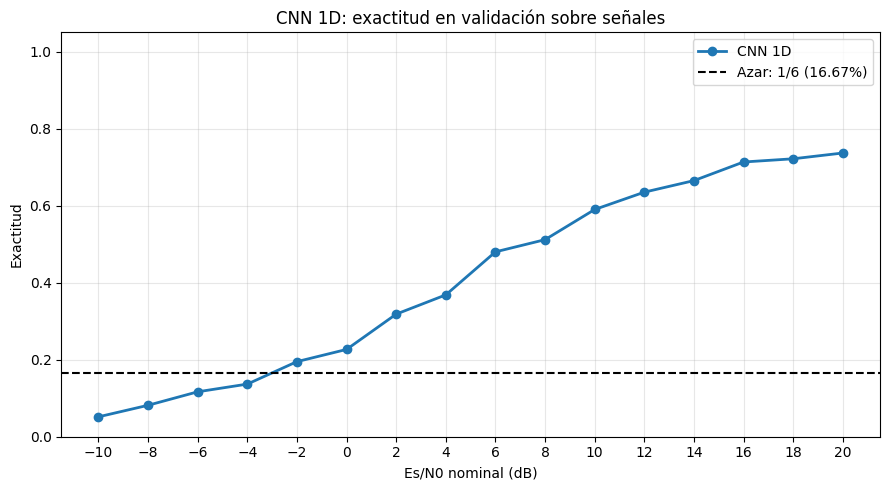

In [29]:
predicted_batches = []
probability_batches = []

with torch.no_grad():
    for signals, labels in val_loader:
        signals = signals.to(device)
        scores = best_cnn(signals)
        probabilities = torch.softmax(scores, dim=1)

        predicted_batches.append(
            scores.argmax(dim=1).cpu().numpy()
        )
        probability_batches.append(
            probabilities.cpu().numpy()
        )

cnn_pred_val = np.concatenate(predicted_batches).astype(np.int64)
cnn_prob_val = np.concatenate(probability_batches)

assert cnn_pred_val.shape == (11200,), (
    "Se esperaban 11200 predicciones, pero hay {}.".format(
        cnn_pred_val.shape[0]
    )
)
assert cnn_prob_val.shape == (11200, len(CLASSES))
assert cnn_pred_val.shape == labels_val.shape

global_accuracy = np.mean(cnn_pred_val == labels_val)

assert "{:.2%}".format(global_accuracy) == "48.59%", (
    "La exactitud global fue {:.2%}, no 48.59%.".format(
        global_accuracy
    )
)

print("Predicciones de val: {}".format(cnn_pred_val.shape[0]))
print("Exactitud global: {:.2%}".format(global_accuracy))

noise_index = len(CLASSES) - 1
assert CLASSES[noise_index] == "ruido"

esn0_levels = np.arange(-10, 22, 2)
accuracy_by_esn0 = []
sent_to_noise_by_esn0 = []

print(
    "{:>10} | {:>14} | {:>9} | {:>16}".format(
        "Es/N0 (dB)",
        "Observaciones",
        "Exactitud",
        "Enviado a ruido"
    )
)

for level in esn0_levels:
    mask = (labels_val != noise_index) & (esn0_val == level)
    count = int(np.count_nonzero(mask))

    assert count == 600, (
        "Se esperaban 600 señales a {} dB; hay {}.".format(
            level, count
        )
    )

    accuracy = np.mean(cnn_pred_val[mask] == labels_val[mask])
    sent_to_noise = np.mean(cnn_pred_val[mask] == noise_index)

    accuracy_by_esn0.append(accuracy)
    sent_to_noise_by_esn0.append(sent_to_noise)

    print(
        "{:>10} | {:>14} | {:>9.2%} | {:>16.2%}".format(
            level, count, accuracy, sent_to_noise
        )
    )

accuracy_by_esn0 = np.asarray(accuracy_by_esn0)
signal_chance = 1.0 / (len(CLASSES) - 1)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    esn0_levels,
    accuracy_by_esn0,
    marker="o",
    linewidth=2,
    label="CNN 1D"
)
ax.axhline(
    signal_chance,
    color="black",
    linestyle="--",
    label="Azar: 1/6 ({:.2%})".format(signal_chance)
)

ax.set_xlabel("Es/N0 nominal (dB)")
ax.set_ylabel("Exactitud")
ax.set_title("CNN 1D: exactitud en validación sobre señales")
ax.set_xticks(esn0_levels)
ax.set_ylim(0.0, 1.05)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

fig.savefig(
    FIG_DIR / "03_exactitud_vs_esn0_val.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    FIG_DIR / "03_exactitud_vs_esn0_val.pdf",
    bbox_inches="tight"
)
print("Figura guardada: 03_exactitud_vs_esn0_val")
plt.show()


Observaciones con Es/N0 ≥ 10 dB, incluido el ruido: 5200
Figura guardada: 04_confusion_conteos_val


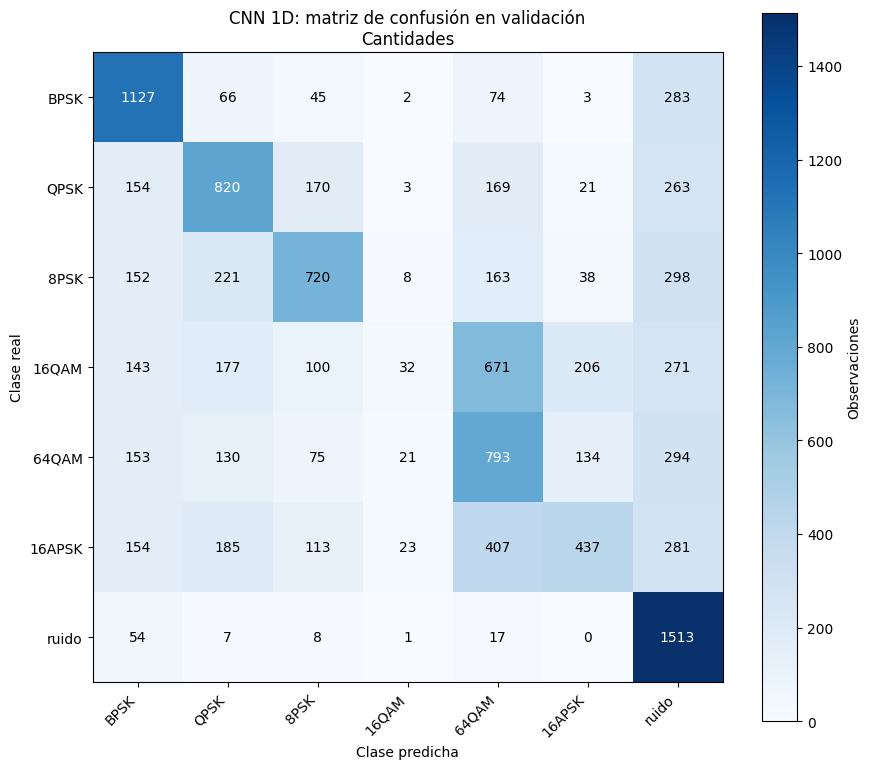

Figura guardada: 05_confusion_porcentajes_val


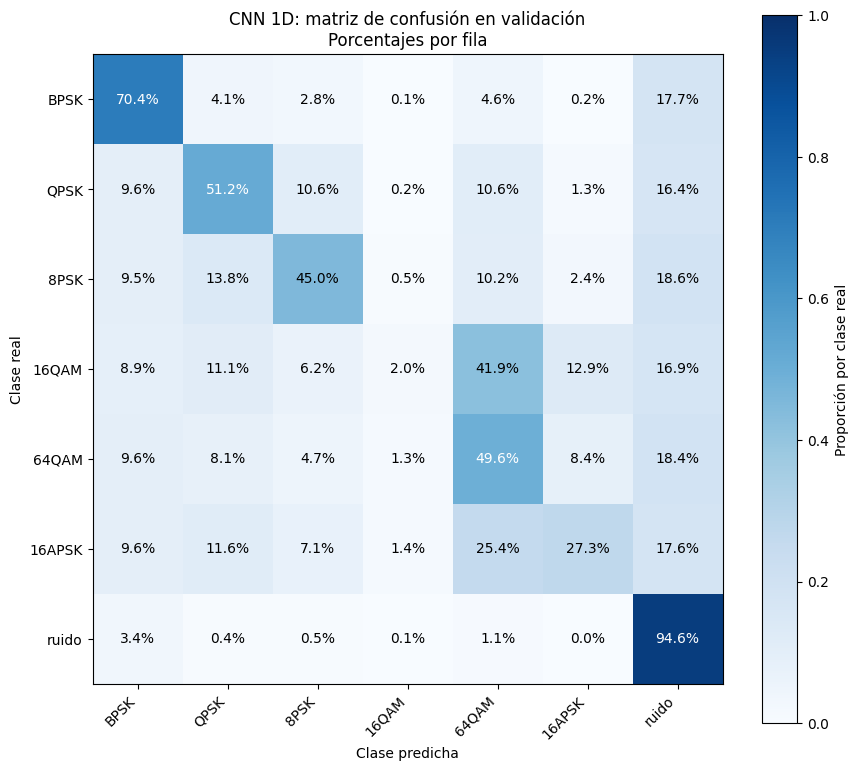

Figura guardada: 06_confusion_conteos_val_esn0_10mas


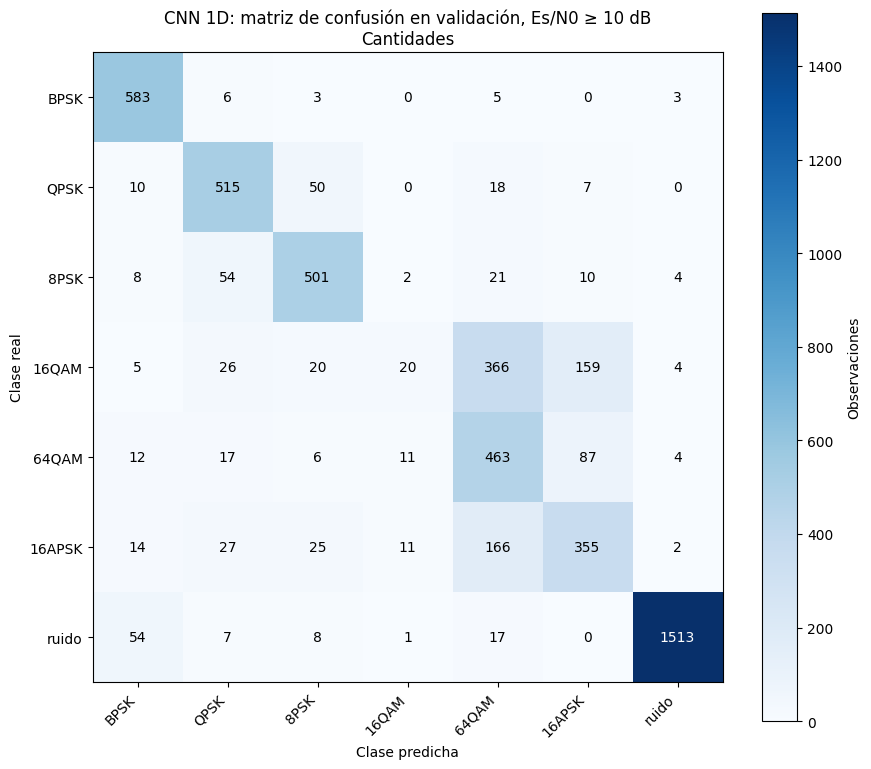

Figura guardada: 07_confusion_porcentajes_val_esn0_10mas


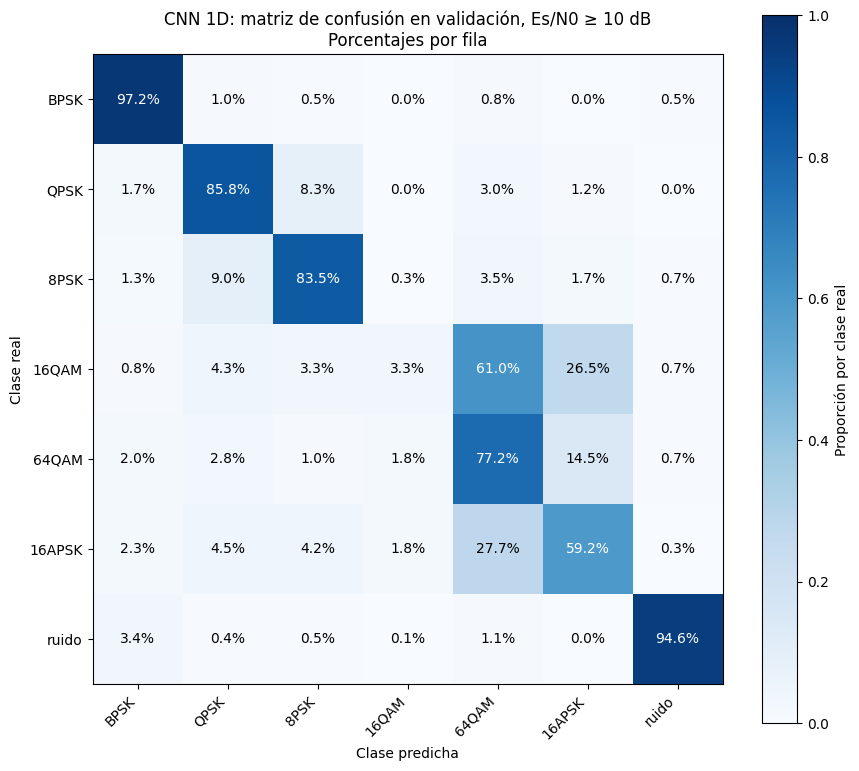

Recall por clase, Es/N0 ≥ 10 dB
  BPSK: 97.17%
  QPSK: 85.83%
  8PSK: 83.50%
  16QAM: 3.33%
  64QAM: 77.17%
  16APSK: 59.17%
  ruido: 94.56%

Errores de cada modulación, Es/N0 ≥ 10 dB: porcentaje que va a ruido y a otras modulaciones
  BPSK: 17.65% a ruido, 82.35% a otras modulaciones (17 errores)
  QPSK: 0.00% a ruido, 100.00% a otras modulaciones (85 errores)
  8PSK: 4.04% a ruido, 95.96% a otras modulaciones (99 errores)
  16QAM: 0.69% a ruido, 99.31% a otras modulaciones (580 errores)
  64QAM: 2.92% a ruido, 97.08% a otras modulaciones (137 errores)
  16APSK: 0.82% a ruido, 99.18% a otras modulaciones (245 errores)

Confusiones más frecuentes entre modulaciones, Es/N0 ≥ 10 dB
16QAM → 64QAM: 366 (61.00%)
16APSK → 64QAM: 166 (27.67%)
16QAM → 16APSK: 159 (26.50%)


In [30]:
def confusion_counts(y_true, y_pred):
    n_classes = len(CLASSES)
    flat_index = y_true * n_classes + y_pred
    counts = np.bincount(
        flat_index,
        minlength=n_classes * n_classes
    )
    return counts.reshape(n_classes, n_classes)


def row_percentages(counts):
    totals = counts.sum(axis=1, keepdims=True).astype(np.float64)
    assert np.all(totals > 0)
    percentages = counts.astype(np.float64) / totals
    assert np.allclose(percentages.sum(axis=1), 1.0)
    return percentages


def plot_confusion(matrix, normalized, filename, title):
    fig, ax = plt.subplots(figsize=(9, 8))

    image = ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=1.0 if normalized else None
    )

    fig.colorbar(
        image,
        ax=ax,
        label=(
            "Proporción por clase real"
            if normalized
            else "Observaciones"
        )
    )

    ticks = np.arange(len(CLASSES))
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(title)

    threshold = matrix.max() / 2.0

    for row in range(len(CLASSES)):
        for column in range(len(CLASSES)):
            if normalized:
                label = "{:.1%}".format(matrix[row, column])
            else:
                label = str(int(matrix[row, column]))

            ax.text(
                column,
                row,
                label,
                ha="center",
                va="center",
                color=(
                    "white"
                    if matrix[row, column] > threshold
                    else "black"
                )
            )

    plt.tight_layout()
    fig.savefig(
        FIG_DIR / (filename + ".png"),
        dpi=300,
        bbox_inches="tight"
    )
    fig.savefig(
        FIG_DIR / (filename + ".pdf"),
        bbox_inches="tight"
    )
    print("Figura guardada: {}".format(filename))
    plt.show()


noise_index = len(CLASSES) - 1
assert CLASSES[noise_index] == "ruido"

cm_val = confusion_counts(labels_val, cnn_pred_val)
assert int(cm_val.sum()) == 11200, (
    "La matriz de val suma {}, no 11200.".format(int(cm_val.sum()))
)
cm_val_percent = row_percentages(cm_val)

high_mask = (labels_val == noise_index) | (esn0_val >= 10.0)
cm_high = confusion_counts(
    labels_val[high_mask],
    cnn_pred_val[high_mask]
)
cm_high_percent = row_percentages(cm_high)

print(
    "Observaciones con Es/N0 ≥ 10 dB, incluido el ruido: {}".format(
        int(high_mask.sum())
    )
)

plot_confusion(
    cm_val,
    False,
    "04_confusion_conteos_val",
    "CNN 1D: matriz de confusión en validación\nCantidades"
)
plot_confusion(
    cm_val_percent,
    True,
    "05_confusion_porcentajes_val",
    "CNN 1D: matriz de confusión en validación\n"
    "Porcentajes por fila"
)
plot_confusion(
    cm_high,
    False,
    "06_confusion_conteos_val_esn0_10mas",
    "CNN 1D: matriz de confusión en validación, Es/N0 ≥ 10 dB\n"
    "Cantidades"
)
plot_confusion(
    cm_high_percent,
    True,
    "07_confusion_porcentajes_val_esn0_10mas",
    "CNN 1D: matriz de confusión en validación, Es/N0 ≥ 10 dB\n"
    "Porcentajes por fila"
)

print("Recall por clase, Es/N0 ≥ 10 dB")

for index, name in enumerate(CLASSES):
    recall = cm_high[index, index] / float(cm_high[index].sum())
    print("  {}: {:.2%}".format(name, recall))

print(
    "\nErrores de cada modulación, Es/N0 ≥ 10 dB: "
    "porcentaje que va a ruido y a otras modulaciones"
)

for index, name in enumerate(CLASSES[:-1]):
    row = cm_high[index]
    errors = int(row.sum() - row[index])
    to_noise = int(row[noise_index])
    to_other = errors - to_noise

    if errors == 0:
        print("  {}: 0 errores".format(name))
        continue

    print(
        "  {}: {:.2%} a ruido, {:.2%} a otras modulaciones "
        "({} errores)".format(
            name,
            to_noise / float(errors),
            to_other / float(errors),
            errors
        )
    )

pairs = []
n_modulations = len(CLASSES) - 1

for real_index in range(n_modulations):
    row_total = float(cm_high[real_index].sum())

    for predicted_index in range(n_modulations):
        if real_index == predicted_index:
            continue

        count = int(cm_high[real_index, predicted_index])
        pairs.append((
            count,
            count / row_total,
            real_index,
            predicted_index
        ))

pairs.sort(key=lambda item: (-item[0], item[2], item[3]))

print(
    "\nConfusiones más frecuentes entre modulaciones, "
    "Es/N0 ≥ 10 dB"
)

for count, share, real_index, predicted_index in pairs[:3]:
    print(
        "{} → {}: {} ({:.2%})".format(
            CLASSES[real_index],
            CLASSES[predicted_index],
            count,
            share
        )
    )
